# Лабораторная работа №1. Методы одномерной оптимизации

**Вариант 18**

$$f(x)=\frac{4x^2}{3+x^2}.$$

Цель работы: аналитически найти экстремумы функции, построить график, выбрать отрезок поиска и сравнить численное решение методами дихотомии, золотого сечения и перебора.

## 1. Аналитическое решение

### Область определения, симметрия и значения

Поскольку $3+x^2>0$ при любом действительном $x$, область определения — $\mathbb R$. Функция чётная: $f(-x)=f(x)$. График симметричен относительно оси $Oy$.

$$f(x)=4-\frac{12}{3+x^2},\qquad 0\leq f(x)<4.$$

Единственный нуль функции — $x=0$. Во всех остальных точках функция положительна. Множество значений: $[0;4)$.

### Производная и экстремумы

По правилу дифференцирования частного:

$$f'(x)=\frac{8x(3+x^2)-4x^2\cdot2x}{(3+x^2)^2}
=\frac{24x}{(3+x^2)^2}.$$

Знаменатель положителен, поэтому знак производной совпадает со знаком $x$:

| x | $(−\infty;0)$ | $0$ | $(0;+\infty)$ |
|---|---|---|---|
| Знак $f'(x)$ | − | 0 | + |
| Поведение $f(x)$ | Убывает | Минимум | Возрастает |

Уравнение $f'(x)=0$ имеет единственный корень $x=0$. Производная меняет знак с минуса на плюс, следовательно,

$$\boxed{x^*=0,\qquad f(x^*)=0.}$$

Это строгий локальный и глобальный минимум. Дополнительная проверка: $f(x)\geq0$ для всех $x$, причём равенство достигается только при $x=0$. Локальных и глобального максимумов на $\mathbb R$ нет: верхняя грань $4$ не достигается.

### Вторая производная и асимптота

$$f''(x)=\frac{24(3+x^2)-96x^2}{(3+x^2)^3}
=\frac{72(1-x^2)}{(3+x^2)^3}.$$

При $|x|<1$ имеем $f''(x)>0$, при $|x|>1$ — $f''(x)<0$. В точках $x=\pm1$ знак второй производной меняется. Точки перегиба: $(-1;1)$ и $(1;1)$. Также $f''(0)=8/3>0$, что подтверждает минимум.

$$\lim_{x\to\pm\infty}f(x)=4.$$

Горизонтальная асимптота — $y=4$. Вертикальных асимптот нет.



## 2. Подготовка
Запускайте ячейки по порядку сверху вниз. Используются только `numpy`, `matplotlib` и стандартный модуль `math`.

In [1]:
from math import ceil, sqrt
import numpy as np
import matplotlib.pyplot as plt


def f(x):
    return 4 * x**2 / (3 + x**2)


a = -2
b = 3
eps = 1e-5

## 3. График функции
Горизонтальная асимптота: $y=4$, минимум: $(0;0)$, точки перегиба: $(−1;1)$ и $(1;1)$.

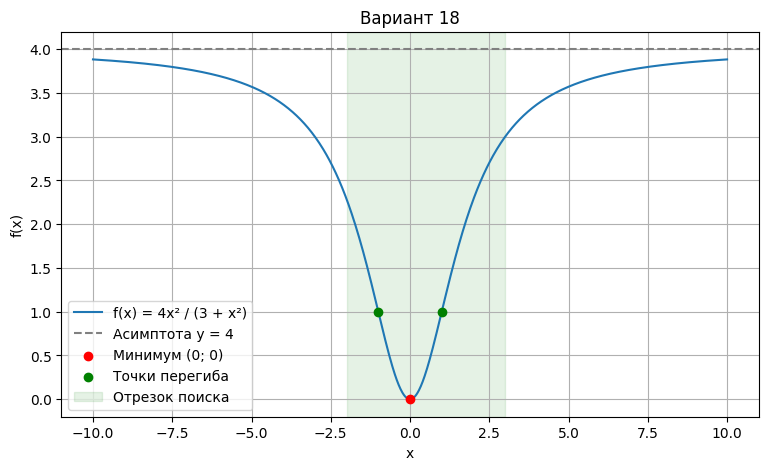

In [2]:
x = np.linspace(-10, 10, 1001)
plt.figure(figsize=(9, 5))
plt.plot(x, f(x), label="f(x) = 4x² / (3 + x²)")
plt.axhline(4, color="gray", linestyle="--", label="Асимптота y = 4")
plt.scatter(0, 0, color="red", label="Минимум (0; 0)", zorder=3)
plt.scatter([-1, 1], [1, 1], color="green", label="Точки перегиба", zorder=3)
plt.axvspan(a, b, alpha=0.1, color="green", label="Отрезок поиска")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Вариант 18")
plt.grid()
plt.legend()
plt.show()

## 4. Численные методы
Ищем минимум на $[-2;3]$ с точностью $\varepsilon=10^{-5}$. Функция убывает до нуля и возрастает после него, поэтому она унимодальна на выбранном отрезке.

В методах дихотомии и золотого сечения останавливаемся при длине отрезка не больше $\varepsilon$. Ответ — середина отрезка, ошибка по $x$ не больше $\varepsilon/2$.

Каждая функция возвращает четыре обычных числа: найденную точку, значение функции, число итераций (для перебора — шагов сетки), число вычислений функции. Счётчик `calls` включает вычисление значения в итоговой точке.

### 4.1. Дихотомия
Берём две точки по сторонам от середины, на расстоянии $\delta=\varepsilon/10$. Сравниваем значения функции и оставляем часть отрезка, содержащую минимум. На каждой итерации вычисляем функцию два раза.

In [3]:
def dichotomy(a, b, eps):
    delta = eps / 10
    iterations = 0
    calls = 0

    while b - a > eps:
        middle = (a + b) / 2
        x1 = middle - delta
        x2 = middle + delta
        y1 = f(x1)
        y2 = f(x2)
        calls += 2

        if y1 <= y2:
            b = x2
        else:
            a = x1
        iterations += 1

    x_min = (a + b) / 2
    y_min = f(x_min)
    calls += 1
    return x_min, y_min, iterations, calls

### 4.2. Золотое сечение
Используем коэффициент $\tau=(\sqrt{5}-1)/2$. Внутренние точки: $x_1=b-\tau(b-a)$ и $x_2=a+\tau(b-a)$.

После сокращения отрезка сохраняем одну точку и уже вычисленное значение функции. Вторую точку вычисляем только тогда, когда нужна следующая итерация.

In [4]:
def golden_section(a, b, eps):
    tau = (sqrt(5) - 1) / 2
    x1 = b - tau * (b - a)
    x2 = a + tau * (b - a)
    y1 = f(x1)
    y2 = f(x2)
    calls = 2
    iterations = 0

    while b - a > eps:
        if y1 <= y2:
            b = x2
            x2 = x1
            y2 = y1
            if b - a > eps:
                x1 = b - tau * (b - a)
                y1 = f(x1)
                calls += 1
        else:
            a = x1
            x1 = x2
            y1 = y2
            if b - a > eps:
                x2 = a + tau * (b - a)
                y2 = f(x2)
                calls += 1
        iterations += 1

    x_min = (a + b) / 2
    y_min = f(x_min)
    calls += 1
    return x_min, y_min, iterations, calls

### 4.3. Перебор
Делим отрезок на $N=\lceil(b-a)/\varepsilon\rceil$ частей. Шаг $h=(b-a)/N$ не больше $\varepsilon$. Проверяем все $N+1$ узлов, включая концы, и выбираем наименьшее значение.

Для нашей функции лучший узел — ближайший к нулю, поэтому ошибка не больше $h/2$. Здесь ноль попадает в сетку точно. Для произвольной унимодальной функции оценка ошибки лучшего узла составляет $h$, а не обязательно $h/2$.

In [5]:
def exhaustive_search(a, b, eps):
    n = ceil((b - a) / eps)
    h = (b - a) / n
    x_min = a
    y_min = f(a)
    calls = 1

    for i in range(1, n + 1):
        x = a + i * h
        if i == n:
            x = b
        y = f(x)
        calls += 1

        if y < y_min:
            x_min = x
            y_min = y

    return x_min, y_min, n, calls

## 5. Результаты
Точный ответ: $x^*=0$, $f(x^*)=0$. Поэтому абсолютная ошибка по аргументу равна `abs(x_min)`.

In [6]:
result_dichotomy = dichotomy(a, b, eps)
result_golden = golden_section(a, b, eps)
result_search = exhaustive_search(a, b, eps)

names = ["Дихотомия", "Золотое сечение", "Перебор"]
results = [result_dichotomy, result_golden, result_search]

print(f"{'Метод':<18} {'x_min':>13} {'f(x_min)':>13} {'Итерации/шаги':>14} {'Вызовы f':>10} {'Ошибка x':>13}")
for name, result in zip(names, results):
    x_min, y_min, iterations, calls = result
    print(f"{name:<18} {x_min:13.6g} {y_min:13.6g} {iterations:14} {calls:10} {abs(x_min):13.6g}")

Метод                      x_min      f(x_min)  Итерации/шаги   Вызовы f      Ошибка x
Дихотомия            6.76837e-07   6.10811e-13             20         41   6.76837e-07
Золотое сечение      1.90545e-06   4.84098e-12             28         30   1.90545e-06
Перебор                        0             0         500000     500001             0


Число шагов перебора и число сокращений отрезка имеют разный смысл. Для сравнения затрат используем число вычислений функции.

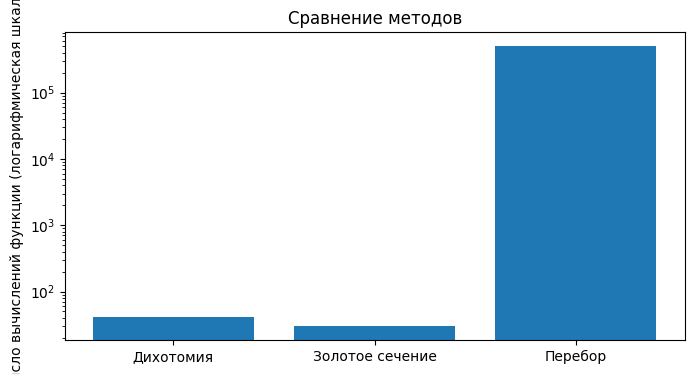

In [7]:
calls = [result_dichotomy[3], result_golden[3], result_search[3]]
plt.figure(figsize=(8, 4))
plt.bar(names, calls)
plt.yscale("log")
plt.ylabel("Число вычислений функции (логарифмическая шкала)")
plt.title("Сравнение методов")
plt.show()

## 6. Вывод
Все три метода подтвердили аналитический минимум: $x^*=0$, $f(x^*)=0$.

- Дихотомия: 20 итераций, 41 вычисление функции.
- Золотое сечение: 28 итераций, 30 вычислений функции.
- Перебор: 500000 шагов, 500001 вычисление функции.

Золотое сечение оказалось наиболее экономным по числу вычислений функции благодаря сохранению ранее найденных значений. Перебор проще, но требует значительно больше вычислений. Его точное попадание в ноль объясняется выбранной сеткой и не гарантируется в других задачах.

При уменьшении $\varepsilon$ затраты перебора растут как $O(1/\varepsilon)$, а интервальных методов — как $O(\log(1/\varepsilon))$ при фиксированной начальной длине отрезка.